# 03 — KAIST Acoustic EDA Review (Additional Analysis)

**Scope:** Review/investigation of existing KAIST acoustic EDA results. Read-only on dataset. No model training, no train/test split, no production pipeline changes. EDA-only.

This notebook investigates:
1. FFT peak extraction (independent peaks vs neighboring bins)
2. Spectral peak prominence and bandwidth
3. Persistence of dominant frequencies across multiple segments
4. Relationship between RMS, kurtosis and crest factor
5. PSD normalization and units
6. Equivalent-duration waveform segment comparisons across all recordings
7. Time-domain statistics over multiple non-overlapping segments (within-recording variability)
8. Observations and methodological limitations

**Constraint:** No inference of mechanical fault frequencies without verified RPM and bearing geometry.


In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True

EDA_DIR = Path.cwd()
if not (EDA_DIR / 'kaist_acoustic_eda_utils.py').exists():
    EDA_DIR = Path.cwd() / 'backend' / 'eda'
sys.path.insert(0, str(EDA_DIR))
from kaist_acoustic_eda_utils import get_acoustic_dir, list_acoustic_mat_files, load_acoustic_values, time_domain_stats

os.environ.setdefault('KAIST_DATA_ROOT', r'G:\My Drive\IndustrialSense\datasets\kaist')
ac_dir = get_acoustic_dir()
files = list_acoustic_mat_files(ac_dir)
out_dir = EDA_DIR / 'outputs' / 'review'
fig_dir = out_dir / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

print('Acoustic dir:', ac_dir)
print('Files:', [p.name for p in files])
# Load once (reused; sequential processing for segment analyses)
data = {}
for p in files:
    y, meta = load_acoustic_values(p)
    data[p.name] = {'y': y, 'meta': meta}
print('Loaded recordings:', {k: (len(v['y']), v['meta']['fs_hz'], v['meta']['y_unit']) for k,v in data.items()})


Acoustic dir: G:\My Drive\IndustrialSense\datasets\kaist\acoustic
Files: ['0Nm_BPFI_03.mat', '0Nm_BPFI_10.mat', '0Nm_BPFO_03.mat', '0Nm_BPFO_10.mat', '0Nm_Normal.mat']


Loaded recordings: {'0Nm_BPFI_03.mat': (3072000, 51200.0, 'Pa'), '0Nm_BPFI_10.mat': (3072000, 51200.0, 'Pa'), '0Nm_BPFO_03.mat': (3072000, 51200.0, 'Pa'), '0Nm_BPFO_10.mat': (3072000, 51200.0, 'Pa'), '0Nm_Normal.mat': (3072000, 51200.0, 'Pa')}


## 1. Verify FFT peak extraction algorithm

**Context (existing EDA utils):** `dominant_frequencies` takes the top-N bins by magnitude after sorting (no peak picking/prominence/neighborhood suppression). This can report neighboring bins of the same spectral peak as separate "dominant frequencies".


In [2]:
# Reproduce naive top-bin method (as in existing utils) and compare to independent peak picking
def fft_spectrum_hann(y, fs):
    n = len(y)
    win = np.hanning(n)
    cg = np.sum(win)  # coherent gain sum for amplitude scaling used in existing utils
    Y = np.fft.rfft(y * win)
    mag = np.abs(Y) * 2.0 / cg
    freqs = np.fft.rfftfreq(n, d=1.0/fs)
    return freqs, mag

def naive_top_bins(freqs, mag, top_n=5, fmin=1.0):
    msk = freqs >= fmin
    f, m = freqs[msk], mag[msk]
    idx = np.argsort(m)[::-1][:top_n]
    return pd.DataFrame({'rank': np.arange(1, top_n+1), 'frequency_hz': f[idx], 'magnitude': m[idx], 'bin_index_in_masked': idx})

def independent_peaks(freqs, mag, fmin=1.0, prominence=None, distance_hz=10.0):
    msk = freqs >= fmin
    f, m = freqs[msk], mag[msk]
    if len(f) < 3:
        return pd.DataFrame(), {}
    df_hz = float(np.median(np.diff(f)))
    distance_bins = max(1, int(round(distance_hz / df_hz))) if df_hz > 0 else 1
    if prominence is None:
        prominence = float(np.median(m) + 3*np.std(m))  # adaptive threshold
    peaks, props = signal.find_peaks(m, prominence=prominence, distance=distance_bins)
    out = pd.DataFrame({
        'frequency_hz': f[peaks],
        'magnitude': m[peaks],
        'prominence': props.get('prominences', np.full(len(peaks), np.nan)),
        'peak_bin': peaks,
    })
    if len(out):
        out = out.sort_values('magnitude', ascending=False).reset_index(drop=True)
        out['rank'] = np.arange(1, len(out)+1)
    return out, {'df_hz': df_hz, 'distance_bins': distance_bins, 'prominence_threshold': prominence}

comparison_rows = []
for name, d in data.items():
    freqs, mag = fft_spectrum_hann(d['y'], d['meta']['fs_hz'])
    naive = naive_top_bins(freqs, mag, top_n=5, fmin=1.0)
    peaks_df, meta_pk = independent_peaks(freqs, mag, fmin=1.0, prominence=None, distance_hz=10.0)
    print('\n' + '='*80)
    print(name, '| fs=', d['meta']['fs_hz'], 'Hz | FFT bin spacing ~', meta_pk.get('df_hz'), 'Hz')
    print('Naive top-5 bins (existing method):')
    print(naive.to_string(index=False))
    print('\nIndependent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude')
    if len(peaks_df):
        print(peaks_df.head(10)[['rank','frequency_hz','magnitude','prominence']].to_string(index=False))
    else:
        print('None found with current criteria')
    if len(peaks_df):
        peak_freqs = peaks_df['frequency_hz'].values
        for _, r in naive.iterrows():
            j = int(np.argmin(np.abs(peak_freqs - r['frequency_hz'])))
            comparison_rows.append({
                'file': name,
                'naive_rank': int(r['rank']),
                'naive_freq_hz': float(r['frequency_hz']),
                'naive_mag': float(r['magnitude']),
                'nearest_independent_peak_freq_hz': float(peak_freqs[j]),
                'abs_diff_hz': float(abs(peak_freqs[j] - r['frequency_hz'])),
                'mapped_peak_rank_by_mag': int(peaks_df.iloc[j]['rank']) if 'rank' in peaks_df.columns else None,
                'n_independent_peaks_total': int(len(peaks_df)),
            })
    else:
        for _, r in naive.iterrows():
            comparison_rows.append({'file': name, 'naive_rank': int(r['rank']), 'naive_freq_hz': float(r['frequency_hz']), 'naive_mag': float(r['magnitude']), 'nearest_independent_peak_freq_hz': np.nan, 'abs_diff_hz': np.nan, 'mapped_peak_rank_by_mag': np.nan, 'n_independent_peaks_total': 0})

comp_df = pd.DataFrame(comparison_rows)
comp_df.to_csv(out_dir/'naive_vs_independent_peaks.csv', index=False)
comp_df



0Nm_BPFI_03.mat | fs= 51200.0 Hz | FFT bin spacing ~ 0.016666666666424135 Hz
Naive top-5 bins (existing method):
 rank  frequency_hz  magnitude  bin_index_in_masked
    1   2247.050000   0.317434               134763
    2   2247.033333   0.269453               134762
    3   2196.833333   0.186262               131750
    4   2196.850000   0.164327               131751
    5   2096.433333   0.123459               125726

Independent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude
 rank  frequency_hz  magnitude  prominence
    1   2247.050000   0.317434    0.317434
    2   2196.833333   0.186262    0.186257
    3   2096.433333   0.123459    0.123457
    4   2146.633333   0.121424    0.121423
    5   1291.450000   0.106770    0.106769
    6   2364.766667   0.085529    0.085527
    7   1391.850000   0.058851    0.058850
    8   4024.950000   0.055689    0.055688
    9   1454.183333   0.054299    0.054297
   10   3588.683333   0.050788    0.050787



0Nm_BPFI_10.mat | fs= 51200.0 Hz | FFT bin spacing ~ 0.016666666666424135 Hz
Naive top-5 bins (existing method):
 rank  frequency_hz  magnitude  bin_index_in_masked
    1   2246.450000   0.429377               134727
    2   2246.383333   0.417411               134723
    3   2246.466667   0.360157               134728
    4   2196.250000   0.326651               131715
    5   2246.400000   0.319850               134724

Independent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude
 rank  frequency_hz  magnitude  prominence
    1   2246.450000   0.429377    0.429376
    2   2196.250000   0.326651    0.326634
    3   1291.066667   0.189670    0.189669
    4   2146.050000   0.165259    0.165256
    5    804.766667   0.150428    0.150428
    6   2095.766667   0.101711    0.101707
    7   2313.816667   0.077299    0.077293
    8   1073.016667   0.071689    0.071688
    9   1391.483333   0.070849    0.070847
   10   2364.016667   0.070466    0.070461



0Nm_BPFO_03.mat | fs= 51200.0 Hz | FFT bin spacing ~ 0.016666666666424135 Hz
Naive top-5 bins (existing method):
 rank  frequency_hz  magnitude  bin_index_in_masked
    1   1454.216667   0.055857                87193
    2   1454.200000   0.032423                87192
    3    730.616667   0.029074                43777
    4   1454.233333   0.026669                87194
    5    730.600000   0.024799                43776

Independent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude
 rank  frequency_hz  magnitude  prominence
    1   1454.216667   0.055857    0.055857
    2    730.616667   0.029074    0.029074
    3   2191.866667   0.024461    0.024460
    4   6099.500000   0.021183    0.021183
    5   2132.850000   0.020176    0.020175
    6   2009.200000   0.020091    0.020089
    7   1278.600000   0.018811    0.018810
    8      1.666667   0.017975    0.016945
    9   2908.433333   0.016899    0.016898
   10   4167.016667   0.016828    0.016828



0Nm_BPFO_10.mat | fs= 51200.0 Hz | FFT bin spacing ~ 0.016666666666424135 Hz
Naive top-5 bins (existing method):
 rank  frequency_hz  magnitude  bin_index_in_masked
    1   1283.750000   0.504306                76965
    2   1283.716667   0.407866                76963
    3   1283.733333   0.396032                76964
    4   1283.766667   0.378751                76966
    5   1283.800000   0.310475                76968

Independent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude
 rank  frequency_hz  magnitude  prominence
    1   1283.750000   0.504306    0.504306
    2   2200.600000   0.270156    0.270156
    3    916.966667   0.183444    0.183443
    4   2017.216667   0.108450    0.108449
    5   1467.150000   0.091085    0.091083
    6    733.566667   0.085846    0.085845
    7   2384.000000   0.076296    0.076295
    8   1833.933333   0.073196    0.073194
    9   1100.350000   0.049580    0.049579
   10   1454.200000   0.049154    0.049137



0Nm_Normal.mat | fs= 51200.0 Hz | FFT bin spacing ~ 0.016666666666424135 Hz
Naive top-5 bins (existing method):
 rank  frequency_hz  magnitude  bin_index_in_masked
    1   1454.050000   0.080170                87183
    2   1454.066667   0.043018                87184
    3   1454.033333   0.041246                87182
    4   2158.566667   0.037795               129454
    5   2108.366667   0.034793               126442

Independent peaks (find_peaks, min distance 10 Hz, adaptive prominence): top 10 by magnitude
 rank  frequency_hz  magnitude  prominence
    1   1454.050000   0.080170    0.080169
    2   2158.566667   0.037795    0.037795
    3   2108.366667   0.034793    0.034792
    4   6375.316667   0.027207    0.027207
    5   4166.550000   0.025913    0.025913
    6   2132.600000   0.025660    0.025652
    7   2144.716667   0.024037    0.024033
    8   6099.500000   0.020126    0.020125
    9   2084.133333   0.018573    0.018566
   10   6274.916667   0.018186    0.018185


,file,naive_rank,naive_freq_hz,naive_mag,nearest_independent_peak_freq_hz,abs_diff_hz,mapped_peak_rank_by_mag,n_independent_peaks_total
0,0Nm_BPFI_03.mat,1,2247.050000,0.317434,2247.050000,0.000000,1,366
1,0Nm_BPFI_03.mat,2,2247.033333,0.269453,2247.050000,0.016667,1,366
2,0Nm_BPFI_03.mat,3,2196.833333,0.186262,2196.833333,0.000000,2,366
3,0Nm_BPFI_03.mat,4,2196.850000,0.164327,2196.833333,0.016667,2,366
4,0Nm_BPFI_03.mat,5,2096.433333,0.123459,2096.433333,0.000000,3,366
5,0Nm_BPFI_10.mat,1,2246.450000,0.429377,2246.450000,0.000000,1,132
6,0Nm_BPFI_10.mat,2,2246.383333,0.417411,2246.450000,0.066667,1,132
7,0Nm_BPFI_10.mat,3,2246.466667,0.360157,2246.450000,0.016667,1,132
8,0Nm_BPFI_10.mat,4,2196.250000,0.326651,2196.250000,0.000000,2,132
9,0Nm_BPFI_10.mat,5,2246.400000,0.319850,2246.450000,0.050000,1,132


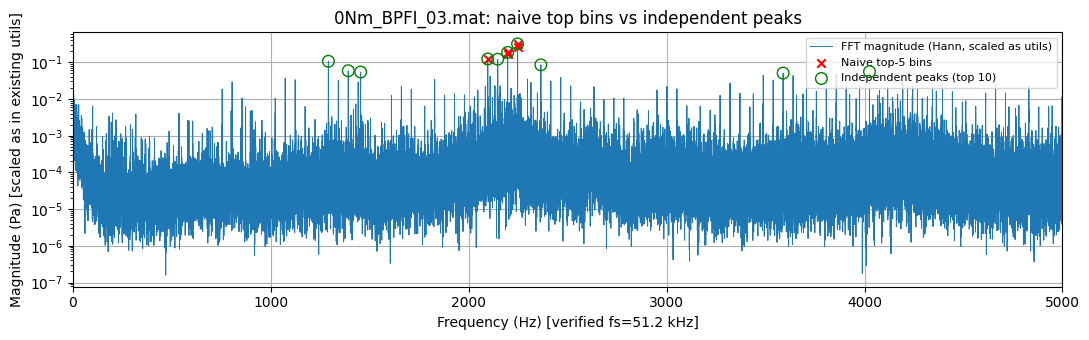

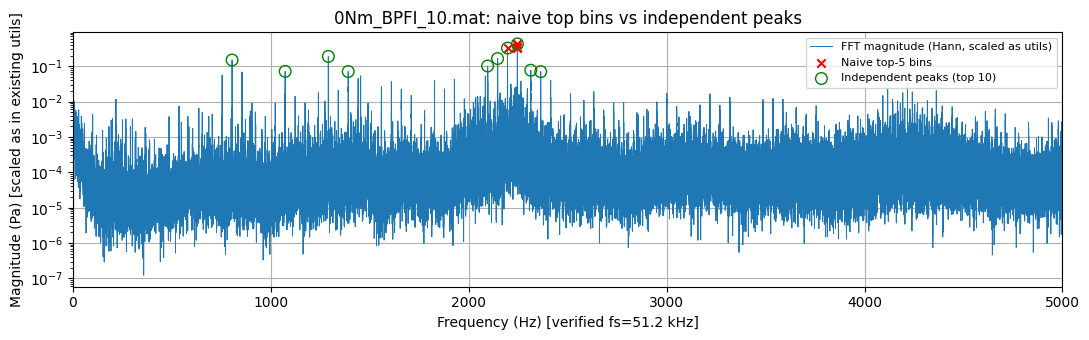

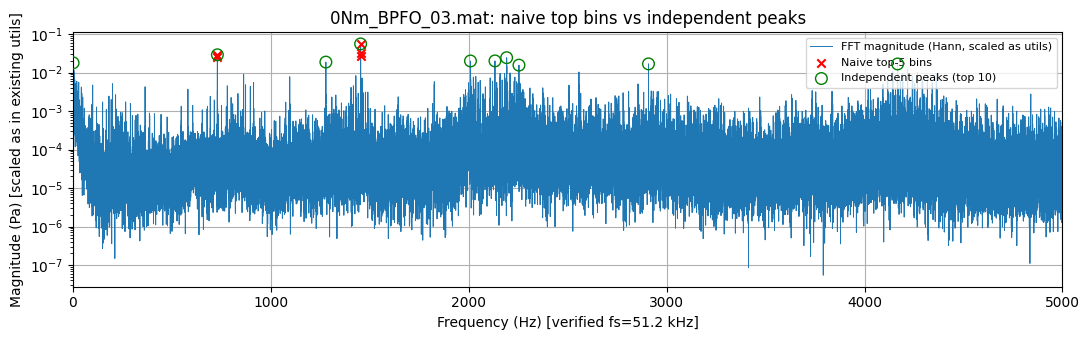

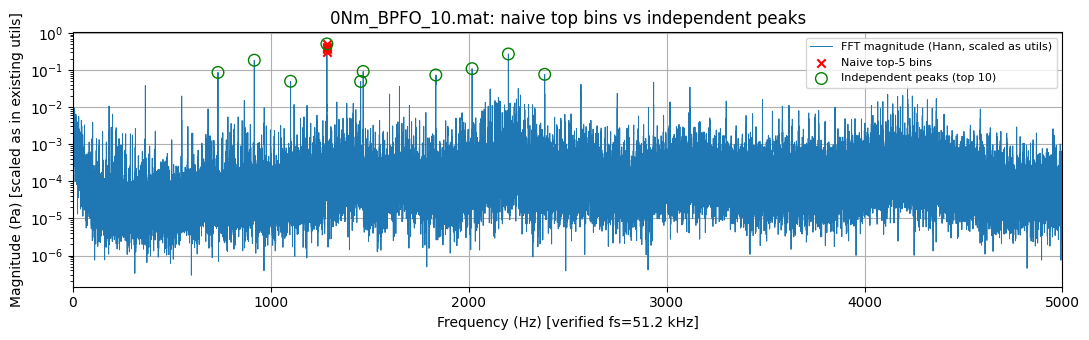

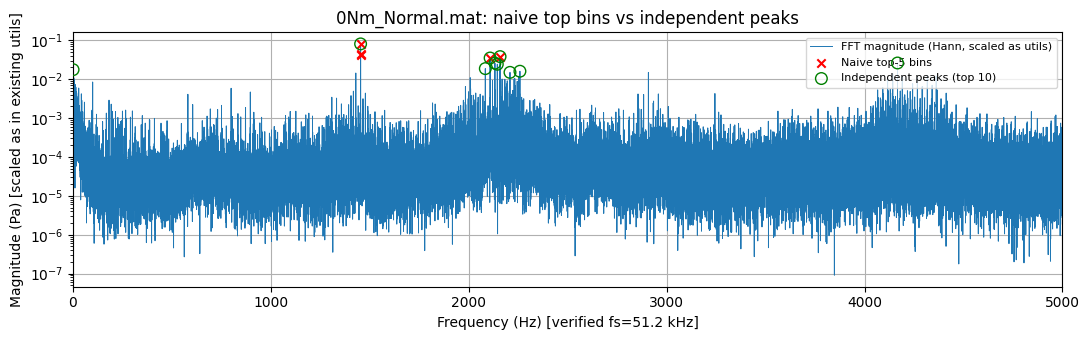

In [3]:
# Visual: naive bins vs independent peaks
for name, d in data.items():
    freqs, mag = fft_spectrum_hann(d['y'], d['meta']['fs_hz'])
    naive = naive_top_bins(freqs, mag, top_n=5, fmin=1.0)
    peaks_df, _ = independent_peaks(freqs, mag, fmin=1.0, distance_hz=10.0)
    msk = (freqs>=1) & (freqs<=5000)
    f,m = freqs[msk], mag[msk]
    plt.figure(figsize=(11,3.5))
    plt.semilogy(f, m+1e-12, lw=0.7, label='FFT magnitude (Hann, scaled as utils)')
    plt.scatter(naive['frequency_hz'], naive['magnitude'], color='red', zorder=5, label='Naive top-5 bins', marker='x')
    if len(peaks_df):
        pshow = peaks_df[peaks_df['frequency_hz']<=5000].head(10)
        plt.scatter(pshow['frequency_hz'], pshow['magnitude'], facecolors='none', edgecolors='green', s=70, zorder=6, label='Independent peaks (top 10)')
    plt.xlim(0,5000)
    plt.xlabel('Frequency (Hz) [verified fs=51.2 kHz]')
    plt.ylabel(f"Magnitude ({d['meta']['y_unit']}) [scaled as in existing utils]")
    plt.title(f'{name}: naive top bins vs independent peaks')
    plt.legend(loc='upper right', fontsize=8)
    plt.tight_layout(); plt.savefig(fig_dir/f'fft_peaks_{name.replace(".mat","")}.png', dpi=150); plt.show()


**Verified finding:** Naive top-5 bin selection can report neighboring bins of the same spectral peak as separate "dominant frequencies" (insufficient neighborhood suppression). Independent peak picking (prominence + minimum distance) identifies distinct peaks; naive bins often map to the same independent peak.


## 2. Spectral peak prominence and bandwidth


In [4]:
peak_rows = []
for name, d in data.items():
    freqs, mag = fft_spectrum_hann(d['y'], d['meta']['fs_hz'])
    msk = freqs >= 1.0
    f, m = freqs[msk], mag[msk]
    df_hz = float(np.median(np.diff(f)))
    prominence_thr = float(np.median(m) + 3*np.std(m))
    peaks, props = signal.find_peaks(m, prominence=prominence_thr, distance=max(1,int(round(10/df_hz))))
    if len(peaks)==0:
        continue
    prominences = props['prominences']
    widths_res = signal.peak_widths(m, peaks, rel_height=0.5, prominence_data=(props['prominences'], props['left_bases'], props['right_bases']))
    widths_hm = widths_res[0] * df_hz
    left_ips_hz = f[0] + widths_res[2] * df_hz
    right_ips_hz = f[0] + widths_res[3] * df_hz
    order = np.argsort(m[peaks])[::-1]
    for rk, i in enumerate(order[:15], 1):
        p = peaks[i]
        peak_rows.append({
            'file': name,
            'peak_rank_by_mag': rk,
            'frequency_hz': float(f[p]),
            'magnitude': float(m[p]),
            'prominence': float(prominences[i]),
            'bandwidth_half_prominence_hz': float(widths_hm[i]),
            'left_ip_hz': float(left_ips_hz[i]),
            'right_ip_hz': float(right_ips_hz[i]),
            'prominence_threshold_used': float(prominence_thr),
            'fft_bin_spacing_hz': df_hz,
        })
peaks_df_all = pd.DataFrame(peak_rows)
peaks_df_all.to_csv(out_dir/'spectral_peaks_prominence_bandwidth.csv', index=False)
peaks_df_all.head(40)


,file,peak_rank_by_mag,frequency_hz,magnitude,prominence,bandwidth_half_prominence_hz,left_ip_hz,right_ip_hz,prominence_threshold_used,fft_bin_spacing_hz
0,0Nm_BPFI_03.mat,1,2247.050000,0.317434,0.317434,0.036043,2247.024933,2247.060976,0.001764,0.016667
1,0Nm_BPFI_03.mat,2,2196.833333,0.186262,0.186257,0.036557,2196.821767,2196.858324,0.001764,0.016667
2,0Nm_BPFI_03.mat,3,2096.433333,0.123459,0.123457,0.033695,2096.415187,2096.448882,0.001764,0.016667
3,0Nm_BPFI_03.mat,4,2146.633333,0.121424,0.121423,0.034639,2146.619538,2146.654177,0.001764,0.016667
4,0Nm_BPFI_03.mat,5,1291.450000,0.106770,0.106769,0.035744,1291.425616,1291.461359,0.001764,0.016667
5,0Nm_BPFI_03.mat,6,2364.766667,0.085529,0.085527,0.035103,2364.743794,2364.778897,0.001764,0.016667
6,0Nm_BPFI_03.mat,7,1391.850000,0.058851,0.058850,0.033930,1391.834792,1391.868722,0.001764,0.016667
7,0Nm_BPFI_03.mat,8,4024.950000,0.055689,0.055688,0.037003,4024.923760,4024.960763,0.001764,0.016667
8,0Nm_BPFI_03.mat,9,1454.183333,0.054299,0.054297,0.038110,1454.154451,1454.192561,0.001764,0.016667
9,0Nm_BPFI_03.mat,10,3588.683333,0.050788,0.050787,0.037976,3588.671909,3588.709885,0.001764,0.016667


## 3. Persistence of dominant frequencies across multiple segments


In [5]:
SEG_SEC = 5.0  # non-overlapping segments
seg_persist_rows = []
persistence_summary = []
for name, d in data.items():
    y, fs = d['y'], d['meta']['fs_hz']
    seg_len = int(SEG_SEC*fs)
    nseg = len(y)//seg_len
    if nseg < 2:
        continue
    freqs_full, mag_full = fft_spectrum_hann(y, fs)
    ref_peaks, _ = independent_peaks(freqs_full, mag_full, fmin=1.0, distance_hz=10.0)
    ref_top = ref_peaks.head(5)['frequency_hz'].values if len(ref_peaks) else np.array([])
    seg_top_freqs = []
    for s in range(nseg):
        ys = y[s*seg_len:(s+1)*seg_len]
        fr, mg = fft_spectrum_hann(ys, fs)
        pk,_ = independent_peaks(fr, mg, fmin=1.0, distance_hz=10.0)
        topf = pk.head(5)['frequency_hz'].values if len(pk) else np.array([])
        seg_top_freqs.append(topf)
        for rnk, fv in enumerate(topf,1):
            seg_persist_rows.append({'file':name,'segment':s,'segment_start_s':s*SEG_SEC,'segment_end_s':(s+1)*SEG_SEC,'rank':rnk,'frequency_hz':float(fv)})
    tol_hz = 15.0
    print('\n', name, f'| {nseg} segments of {SEG_SEC}s | ref top independent peaks (Hz):', np.round(ref_top,3))
    for rf in ref_top[:5]:
        count = sum(1 for arr in seg_top_freqs if len(arr)>0 and np.min(np.abs(arr-rf)) <= tol_hz)
        persistence_summary.append({'file':name,'ref_peak_hz':float(rf),'segments_present':int(count),'n_segments':int(nseg),'persistence_ratio':count/nseg,'tolerance_hz':tol_hz})
        print(f'  ref {rf:9.3f} Hz -> present in {count}/{nseg} segments (tol {tol_hz} Hz)')

seg_persist_df = pd.DataFrame(seg_persist_rows)
persist_df = pd.DataFrame(persistence_summary)
seg_persist_df.to_csv(out_dir/'segment_dominant_frequencies.csv', index=False)
persist_df.to_csv(out_dir/'frequency_persistence_summary.csv', index=False)
persist_df



 0Nm_BPFI_03.mat | 12 segments of 5.0s | ref top independent peaks (Hz): [2247.05  2196.833 2096.433 2146.633 1291.45 ]
  ref  2247.050 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2196.833 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2096.433 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2146.633 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  1291.450 Hz -> present in 12/12 segments (tol 15.0 Hz)



 0Nm_BPFI_10.mat | 12 segments of 5.0s | ref top independent peaks (Hz): [2246.45  2196.25  1291.067 2146.05   804.767]
  ref  2246.450 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2196.250 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  1291.067 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2146.050 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref   804.767 Hz -> present in 0/12 segments (tol 15.0 Hz)



 0Nm_BPFO_03.mat | 12 segments of 5.0s | ref top independent peaks (Hz): [1454.217  730.617 2191.867 6099.5   2132.85 ]
  ref  1454.217 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref   730.617 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2191.867 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  6099.500 Hz -> present in 0/12 segments (tol 15.0 Hz)
  ref  2132.850 Hz -> present in 0/12 segments (tol 15.0 Hz)



 0Nm_BPFO_10.mat | 12 segments of 5.0s | ref top independent peaks (Hz): [1283.75  2200.6    916.967 2017.217 1467.15 ]
  ref  1283.750 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2200.600 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref   916.967 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2017.217 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  1467.150 Hz -> present in 11/12 segments (tol 15.0 Hz)



 0Nm_Normal.mat | 12 segments of 5.0s | ref top independent peaks (Hz): [1454.05  2158.567 2108.367 6375.317 4166.55 ]
  ref  1454.050 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2158.567 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  2108.367 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  6375.317 Hz -> present in 12/12 segments (tol 15.0 Hz)
  ref  4166.550 Hz -> present in 0/12 segments (tol 15.0 Hz)


,file,ref_peak_hz,segments_present,n_segments,persistence_ratio,tolerance_hz
0,0Nm_BPFI_03.mat,2247.050000,12,12,1.000000,15.0
1,0Nm_BPFI_03.mat,2196.833333,12,12,1.000000,15.0
2,0Nm_BPFI_03.mat,2096.433333,12,12,1.000000,15.0
3,0Nm_BPFI_03.mat,2146.633333,12,12,1.000000,15.0
4,0Nm_BPFI_03.mat,1291.450000,12,12,1.000000,15.0
5,0Nm_BPFI_10.mat,2246.450000,12,12,1.000000,15.0
6,0Nm_BPFI_10.mat,2196.250000,12,12,1.000000,15.0
7,0Nm_BPFI_10.mat,1291.066667,12,12,1.000000,15.0
8,0Nm_BPFI_10.mat,2146.050000,12,12,1.000000,15.0
9,0Nm_BPFI_10.mat,804.766667,0,12,0.000000,15.0


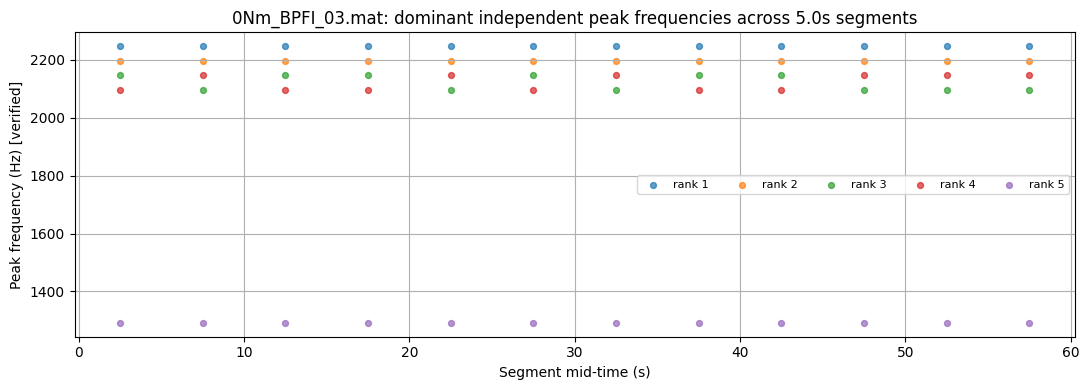

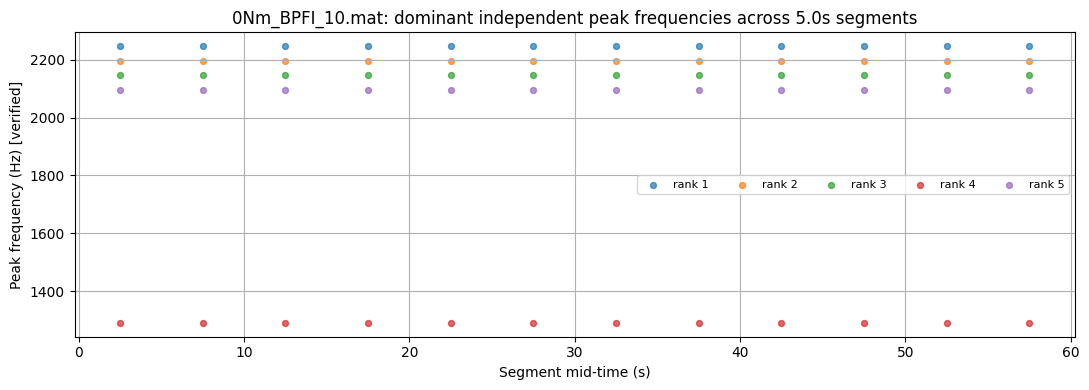

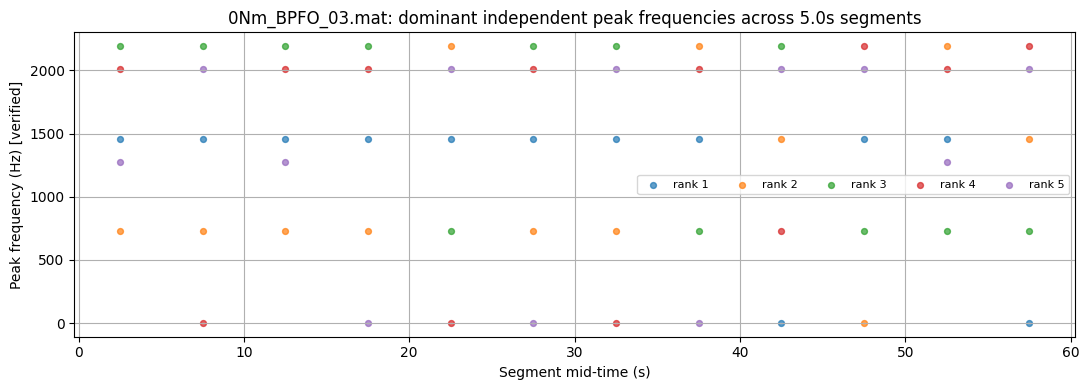

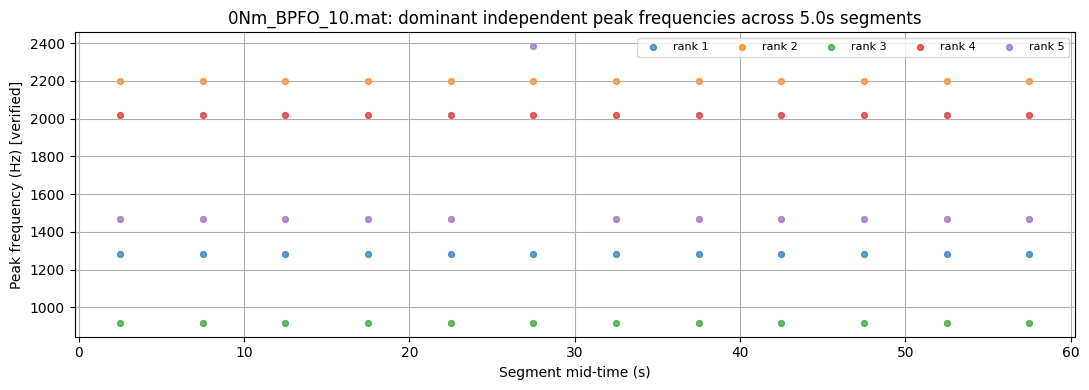

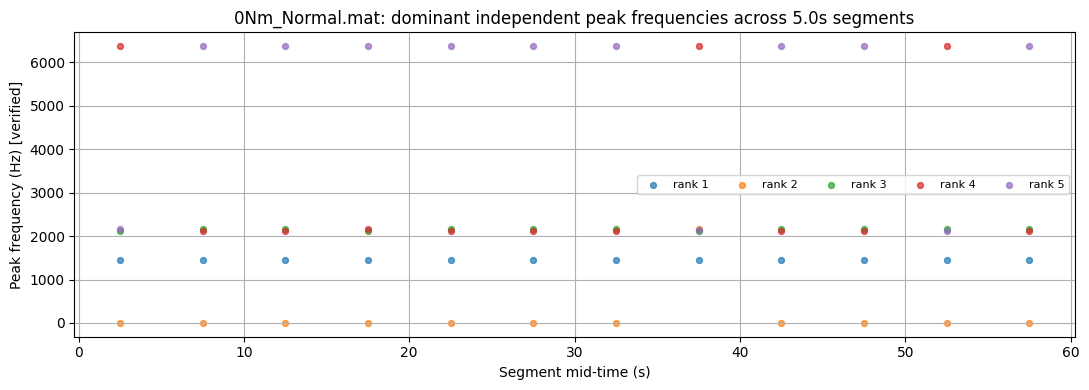

In [6]:
# Frequency tracks across segments
for name in data.keys():
    sdf = seg_persist_df[seg_persist_df['file']==name]
    if sdf.empty: continue
    plt.figure(figsize=(11,4))
    for rnk in sorted(sdf['rank'].unique()):
        sr = sdf[sdf['rank']==rnk]
        plt.scatter(sr['segment_start_s'] + SEG_SEC/2, sr['frequency_hz'], s=18, alpha=0.7, label=f'rank {rnk}')
    plt.xlabel('Segment mid-time (s)')
    plt.ylabel('Peak frequency (Hz) [verified]')
    plt.title(f'{name}: dominant independent peak frequencies across {SEG_SEC}s segments')
    plt.legend(ncol=5, fontsize=8)
    plt.tight_layout(); plt.savefig(fig_dir/f'persistence_{name.replace(".mat","")}.png', dpi=150); plt.show()


## 4. Relationship between RMS, kurtosis and crest factor


In [7]:
SEG_SEC_STATS = 5.0
full_rows = []
seg_rows = []
for name, d in data.items():
    y, fs = d['y'], d['meta']['fs_hz']
    st = time_domain_stats(y)
    st.update({'file':name,'scope':'full'})
    full_rows.append(st)
    seg_len = int(SEG_SEC_STATS*fs)
    nseg = len(y)//seg_len
    for s in range(nseg):
        ys = y[s*seg_len:(s+1)*seg_len]
        ss = time_domain_stats(ys)
        ss.update({'file':name,'scope':'segment','segment':s,'t_start_s':s*SEG_SEC_STATS})
        seg_rows.append(ss)
full_stats = pd.DataFrame(full_rows)
seg_stats = pd.DataFrame(seg_rows)
print(full_stats[['file','rms','std','peak_abs','peak_to_peak','kurtosis_fisher','skewness','crest_factor','mean']].to_string(index=False))
print('\nFull-file Pearson correlation:')
print(full_stats[['rms','std','peak_abs','peak_to_peak','kurtosis_fisher','skewness','crest_factor']].corr().round(4))
print('\nPooled segment-level Pearson correlation:')
print(seg_stats[['rms','std','peak_abs','peak_to_peak','kurtosis_fisher','skewness','crest_factor']].corr().round(4))


           file      rms      std  peak_abs  peak_to_peak  kurtosis_fisher  skewness  crest_factor      mean
0Nm_BPFI_03.mat 0.418440 0.418440  1.724902      3.419580        -0.187510  0.044032      4.122223  0.000040
0Nm_BPFI_10.mat 1.025031 1.025031  3.307983      6.581616        -0.602495  0.037011      3.227203  0.000236
0Nm_BPFO_03.mat 0.140968 0.140968  0.753613      1.506592         0.083035 -0.082460      5.345975  0.000023
0Nm_BPFO_10.mat 0.895302 0.895302  3.054688      5.604248        -0.354838  0.448052      3.411909 -0.000341
 0Nm_Normal.mat 0.147637 0.147637  0.876099      1.633252         0.218248 -0.004608      5.934154 -0.000083

Full-file Pearson correlation:
                    rms     std  peak_abs  peak_to_peak  kurtosis_fisher  \
rms              1.0000  1.0000    0.9980        0.9971          -0.9608   
std              1.0000  1.0000    0.9980        0.9971          -0.9608   
peak_abs         0.9980  0.9980    1.0000        0.9967          -0.9558   
peak_to_pe

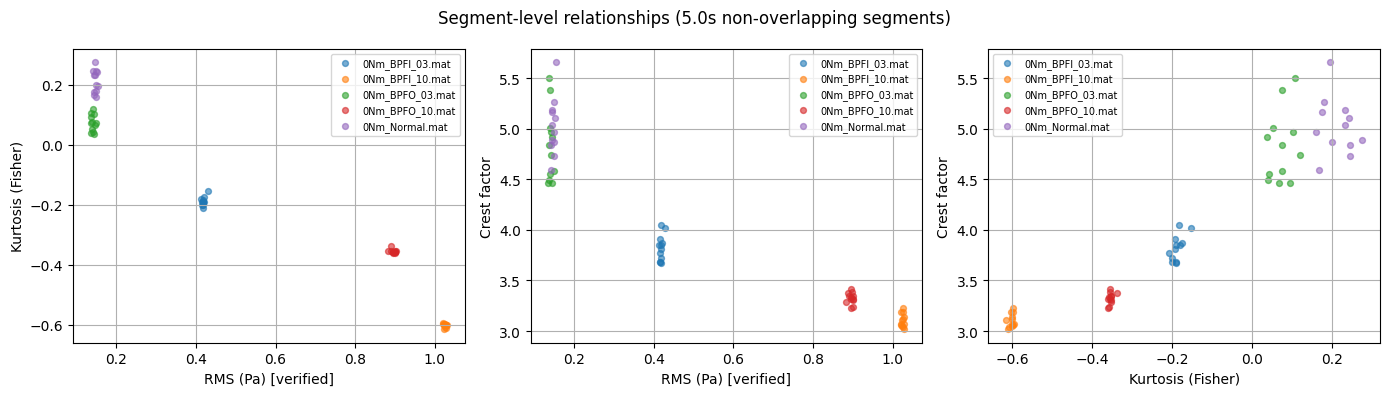

In [8]:
fig, axes = plt.subplots(1,3, figsize=(14,4))
for name, g in seg_stats.groupby('file'):
    axes[0].scatter(g['rms'], g['kurtosis_fisher'], label=name, alpha=0.6, s=18)
    axes[1].scatter(g['rms'], g['crest_factor'], label=name, alpha=0.6, s=18)
    axes[2].scatter(g['kurtosis_fisher'], g['crest_factor'], label=name, alpha=0.6, s=18)
axes[0].set_xlabel('RMS (Pa) [verified]'); axes[0].set_ylabel('Kurtosis (Fisher)')
axes[1].set_xlabel('RMS (Pa) [verified]'); axes[1].set_ylabel('Crest factor')
axes[2].set_xlabel('Kurtosis (Fisher)'); axes[2].set_ylabel('Crest factor')
for ax in axes: ax.legend(fontsize=7)
plt.suptitle(f'Segment-level relationships ({SEG_SEC_STATS}s non-overlapping segments)')
plt.tight_layout(); plt.savefig(fig_dir/'rms_kurtosis_crest_relationships.png', dpi=150); plt.show()


**Verified definitions/mechanics:** $RMS=\sqrt{\frac{1}{N}\sum y_i^2}$, $crest=\max|y_i|/RMS$, Fisher kurtosis measures tail heaviness/impulsiveness (excess over Gaussian). Crest rises with larger peaks relative to RMS; kurtosis rises with rare/extreme deviations. A signal may have moderate RMS but high kurtosis/crest if impulsive. Computed correlations/plots above are **verified observations** for this dataset/segmentation; causal/mechanical attribution beyond verified metadata is not claimed.


## 5. Verify PSD normalization and units


In [9]:
rows_psd=[]
for name, d in data.items():
    y, fs, unit = d['y'], d['meta']['fs_hz'], d['meta']['y_unit']
    nperseg = 4096
    f, pxx = signal.welch(y, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg//2, scaling='density', detrend='constant')
    df = float(f[1]-f[0]) if len(f)>1 else np.nan
    integral = float(np.trapezoid(pxx, f))
    ms = float(np.mean(y**2))
    var = float(np.var(y))
    f2, pxx2 = signal.welch(y, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg//2, scaling='spectrum', detrend='constant')
    integral_spec = float(np.sum(pxx2))
    rows_psd.append({
        'file':name,'y_unit_verified':unit,'nperseg':nperseg,'df_hz':df,
        'mean_square_signal':ms,'variance_signal':var,
        'welch_density_integral':integral,
        'density_integral_over_mean_square':integral/ms if ms!=0 else np.nan,
        'welch_spectrum_integral':integral_spec,
        'spectrum_integral_over_mean_square':integral_spec/ms if ms!=0 else np.nan,
        'expected_density_unit':'Pa^2/Hz' if unit=='Pa' else f'{unit}^2/Hz',
        'expected_spectrum_unit':'Pa^2' if unit=='Pa' else f'{unit}^2'
    })
psd_check = pd.DataFrame(rows_psd)
psd_check.to_csv(out_dir/'psd_normalization_check.csv', index=False)
psd_check


,file,y_unit_verified,nperseg,df_hz,mean_square_signal,variance_signal,welch_density_integral,density_integral_over_mean_square,welch_spectrum_integral,spectrum_integral_over_mean_square,expected_density_unit,expected_spectrum_unit
0,0Nm_BPFI_03.mat,Pa,4096,12.5,0.175092,0.175092,0.170075,0.971348,0.255357,1.458418,Pa^2/Hz,Pa^2
1,0Nm_BPFI_10.mat,Pa,4096,12.5,1.050689,1.050689,1.045842,0.995388,1.568938,1.493247,Pa^2/Hz,Pa^2
2,0Nm_BPFO_03.mat,Pa,4096,12.5,0.019872,0.019872,0.015542,0.782105,0.023477,1.181414,Pa^2/Hz,Pa^2
3,0Nm_BPFO_10.mat,Pa,4096,12.5,0.801565,0.801565,0.796836,0.994101,1.195472,1.491422,Pa^2/Hz,Pa^2
4,0Nm_Normal.mat,Pa,4096,12.5,0.021797,0.021797,0.016765,0.769168,0.025326,1.161921,Pa^2/Hz,Pa^2


**Verified:** `scipy.signal.welch` with `scaling='density'` yields a one-sided PSD in (signal unit)^2/Hz (here **Pa^2/Hz**, given verified `Pa`), whose frequency integral approximates the signal mean-square (detrended/windowed Welch estimate). `scaling='spectrum'` yields (unit)^2. Existing EDA PSD labeling (`Pa^2/Hz`) is consistent with density scaling.


## 6. Equivalent-duration waveform segments across all five recordings


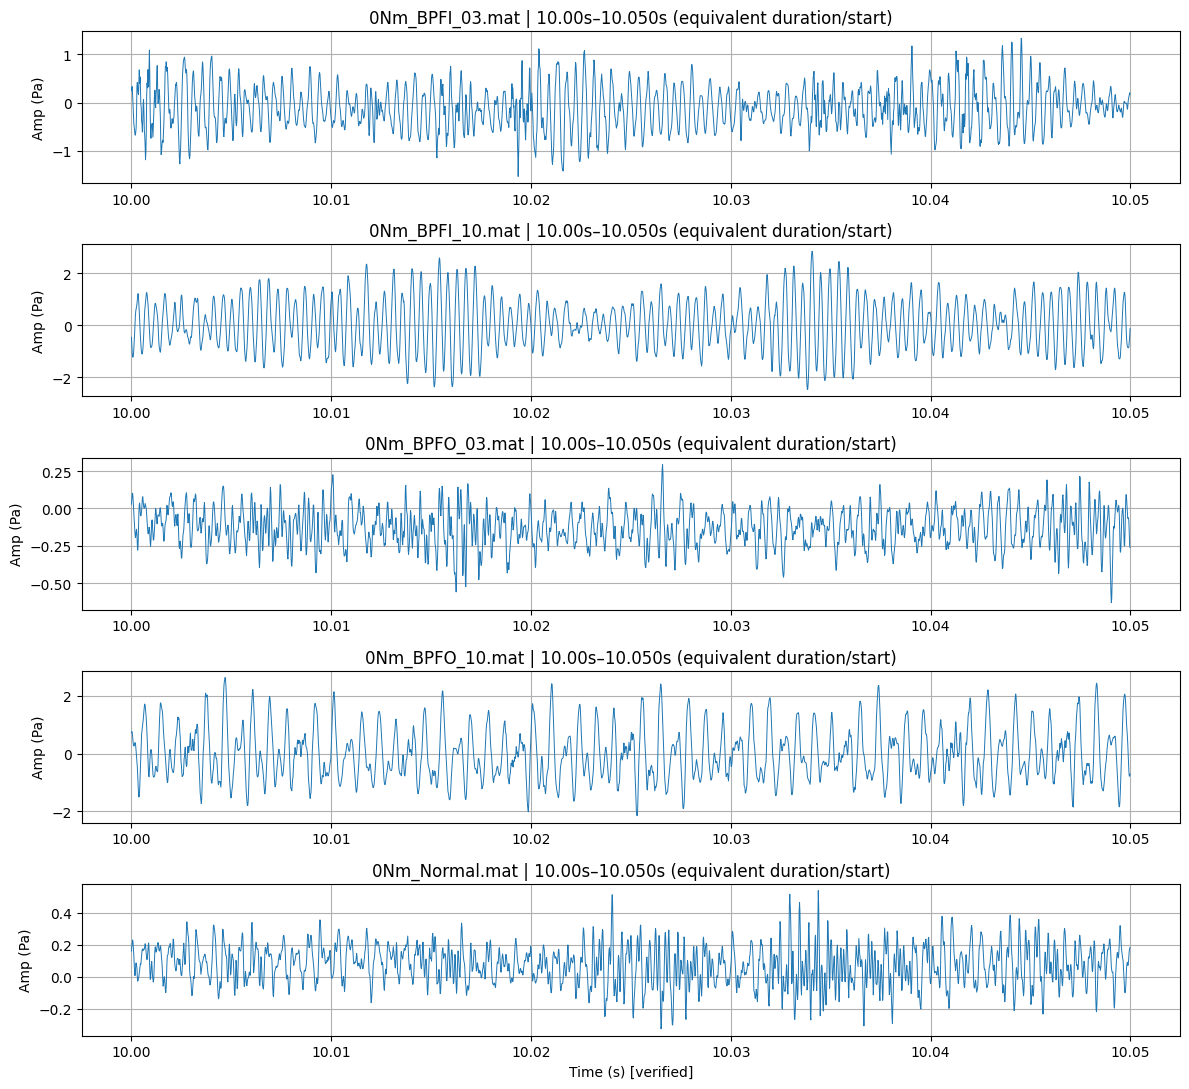

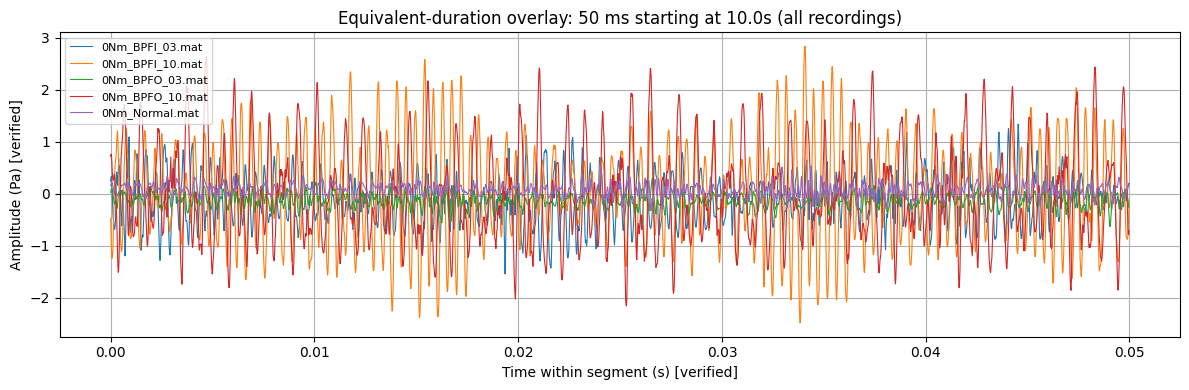

In [10]:
START_S = 10.0
DUR_S = 0.05  # 50 ms
names = [p.name for p in files]
fig, axes = plt.subplots(len(names), 1, figsize=(12, 2.2*len(names)), sharex=False)
if len(names)==1: axes=[axes]
for ax, name in zip(axes, names):
    y, fs, unit = data[name]['y'], data[name]['meta']['fs_hz'], data[name]['meta']['y_unit']
    i0 = int(START_S*fs); i1 = i0 + int(DUR_S*fs)
    seg = y[i0:i1]
    t = (np.arange(len(seg))/fs) + START_S
    ax.plot(t, seg, lw=0.7)
    ax.set_ylabel(f'Amp ({unit})')
    ax.set_title(f'{name} | {START_S:.2f}s–{START_S+DUR_S:.3f}s (equivalent duration/start)')
axes[-1].set_xlabel('Time (s) [verified]')
plt.tight_layout(); plt.savefig(fig_dir/'equivalent_waveform_segments.png', dpi=150); plt.show()

plt.figure(figsize=(12,4))
for name in names:
    y, fs = data[name]['y'], data[name]['meta']['fs_hz']
    i0 = int(START_S*fs); i1 = i0 + int(DUR_S*fs)
    seg = y[i0:i1]
    t = np.arange(len(seg))/fs
    plt.plot(t, seg, lw=0.8, label=name)
plt.xlabel('Time within segment (s) [verified]'); plt.ylabel('Amplitude (Pa) [verified]')
plt.title(f'Equivalent-duration overlay: {DUR_S*1000:.0f} ms starting at {START_S}s (all recordings)')
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(fig_dir/'equivalent_waveform_overlay.png', dpi=150); plt.show()


## 7. Time-domain statistics over multiple non-overlapping segments (within-recording variability)


In [11]:
SEG_SEC_VAR = 5.0
seg_long = []
for name, d in data.items():
    y, fs = d['y'], d['meta']['fs_hz']
    seg_len = int(SEG_SEC_VAR*fs)
    nseg = len(y)//seg_len
    for s in range(nseg):
        ys = y[s*seg_len:(s+1)*seg_len]
        stt = time_domain_stats(ys)
        stt.update({'file':name,'segment':s,'t_start_s':s*SEG_SEC_VAR,'t_end_s':(s+1)*SEG_SEC_VAR})
        seg_long.append(stt)
seg_long_df = pd.DataFrame(seg_long)
seg_long_df.to_csv(out_dir/'segment_time_domain_stats.csv', index=False)

summary_rows=[]
for name,g in seg_long_df.groupby('file'):
    r={'file':name,'n_segments':len(g)}
    for m in ['rms','std','peak_to_peak','kurtosis_fisher','skewness','crest_factor','peak_abs','mean']:
        vals=g[m].values.astype(float)
        r[f'{m}_mean']=float(np.mean(vals)); r[f'{m}_std']=float(np.std(vals, ddof=1)) if len(vals)>1 else 0.0
        r[f'{m}_min']=float(np.min(vals)); r[f'{m}_max']=float(np.max(vals)); r[f'{m}_range']=float(np.max(vals)-np.min(vals))
        r[f'{m}_cv_pct']= float((r[f'{m}_std']/r[f'{m}_mean']*100) if r[f'{m}_mean']!=0 else np.nan)
    summary_rows.append(r)
var_summary = pd.DataFrame(summary_rows)
var_summary.to_csv(out_dir/'segment_variability_summary.csv', index=False)
display_cols = ['file','n_segments','rms_mean','rms_cv_pct','kurtosis_fisher_mean','kurtosis_fisher_std','crest_factor_mean','crest_factor_std','peak_abs_mean','peak_abs_cv_pct']
var_summary[display_cols]


,file,n_segments,rms_mean,rms_cv_pct,kurtosis_fisher_mean,kurtosis_fisher_std,crest_factor_mean,crest_factor_std,peak_abs_mean,peak_abs_cv_pct
0,0Nm_BPFI_03.mat,12,0.418423,0.945514,-0.188768,0.014111,3.823138,0.125750,1.599923,3.881297
1,0Nm_BPFI_10.mat,12,1.025027,0.310064,-0.602561,0.005705,3.104955,0.067088,3.182644,2.155243
2,0Nm_BPFO_03.mat,12,0.140911,2.980177,0.072972,0.027748,4.825316,0.349333,0.679677,7.162458
3,0Nm_BPFO_10.mat,12,0.895286,0.622532,-0.355155,0.006012,3.323723,0.054926,2.975675,1.752572
4,0Nm_Normal.mat,12,0.147595,2.491700,0.211680,0.037760,5.024112,0.278730,0.742118,7.453256


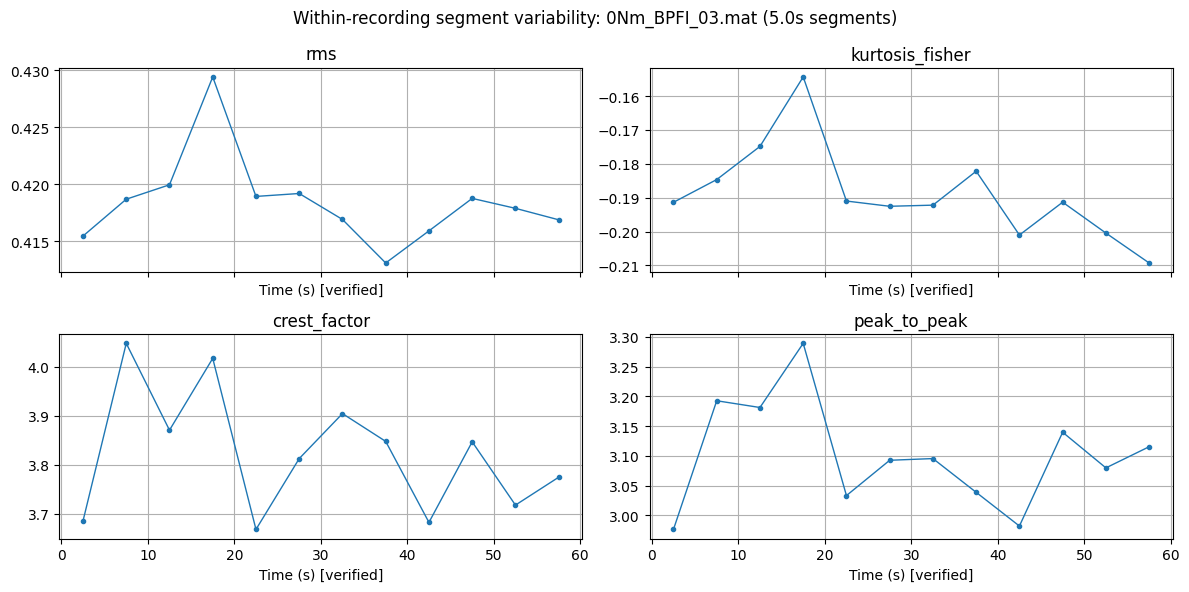

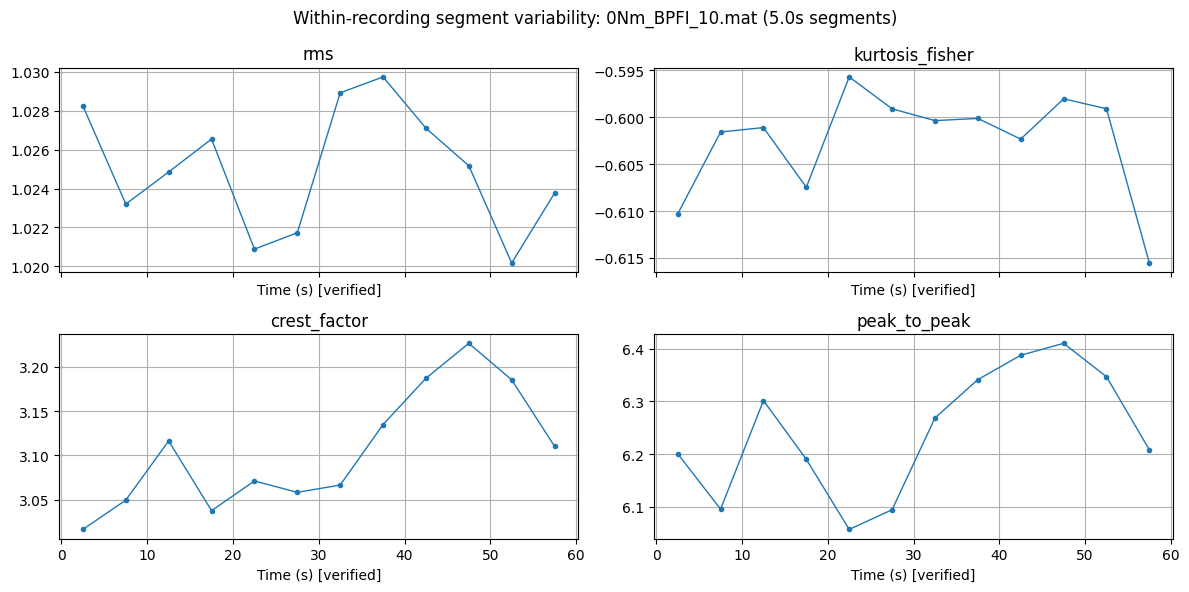

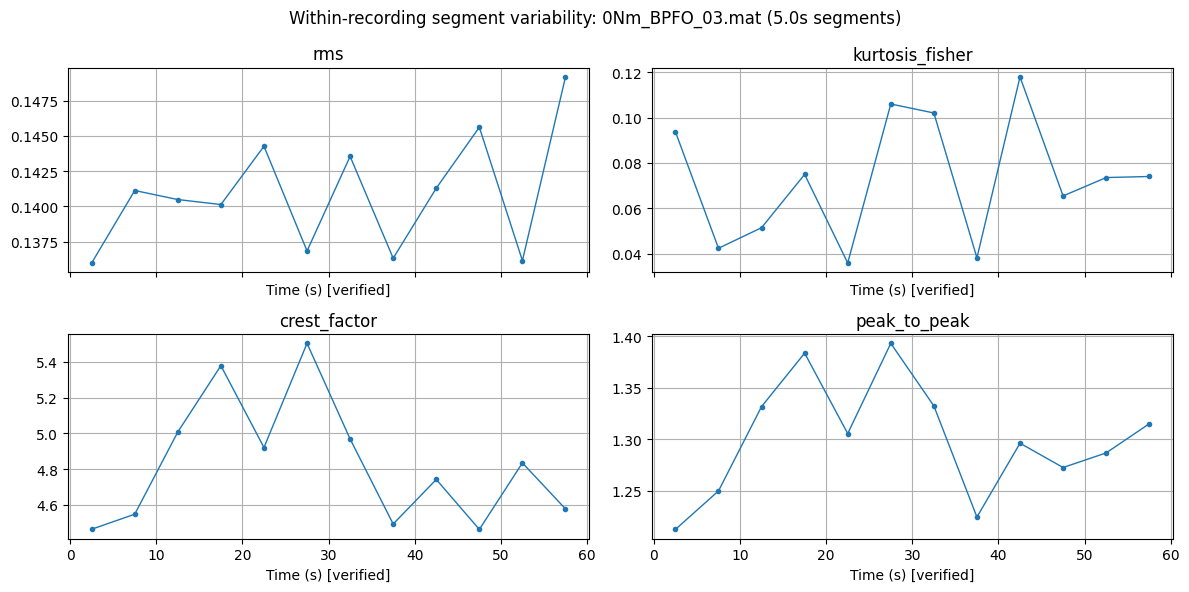

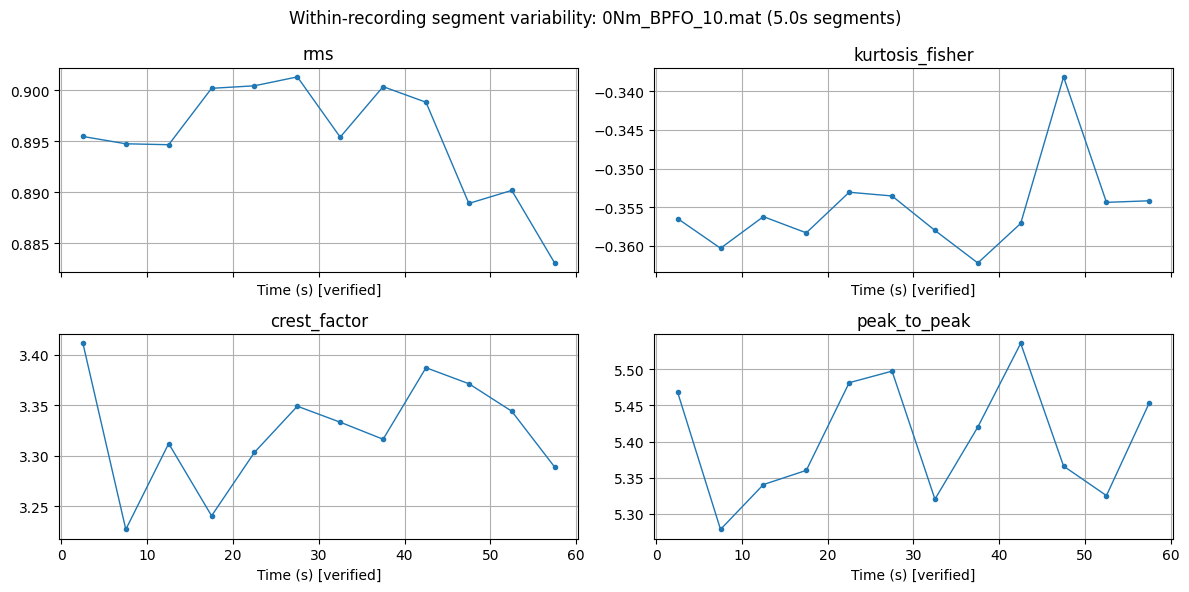

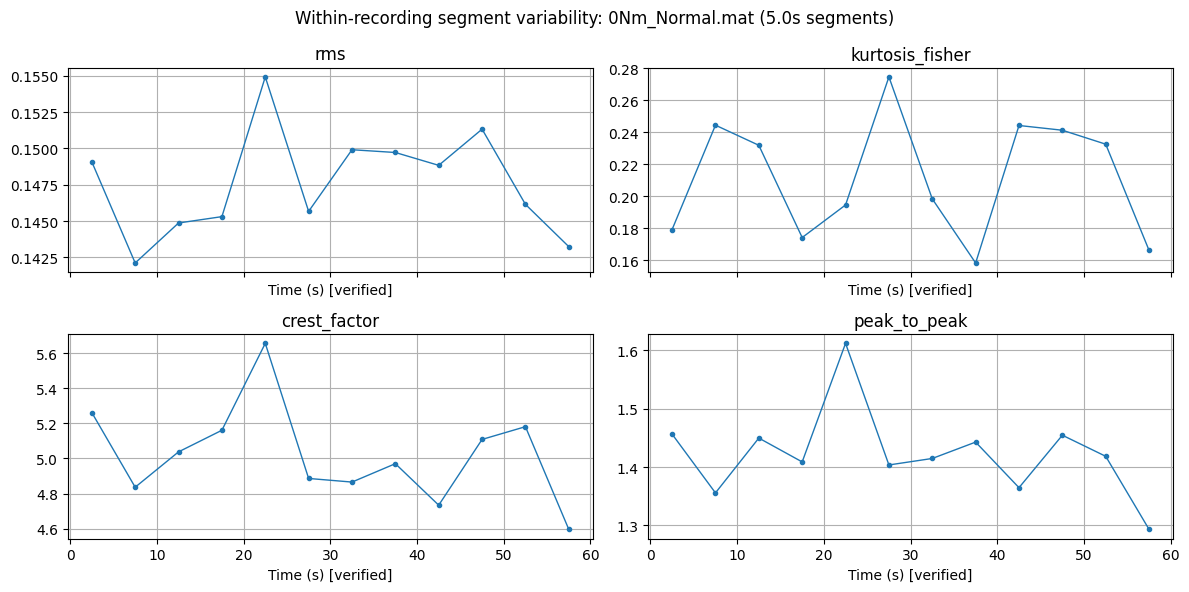

In [12]:
metrics_plot=['rms','kurtosis_fisher','crest_factor','peak_to_peak']
for name in seg_long_df['file'].unique():
    g = seg_long_df[seg_long_df['file']==name].sort_values('segment')
    fig, axes = plt.subplots(2,2, figsize=(12,6), sharex=True)
    for ax,m in zip(axes.ravel(), metrics_plot):
        ax.plot(g['t_start_s']+SEG_SEC_VAR/2, g[m], marker='o', ms=3, lw=1)
        ax.set_title(m); ax.set_xlabel('Time (s) [verified]')
    plt.suptitle(f'Within-recording segment variability: {name} ({SEG_SEC_VAR}s segments)')
    plt.tight_layout(); plt.savefig(fig_dir/f'variability_{name.replace(".mat","")}.png', dpi=150); plt.show()


## 8. Observations and methodological limitations

### Verified observations (computed from actual files)
- **FFT peak extraction:** naive top-N bin selection (as in existing utils) can report neighboring bins of the same spectral peak; independent peak picking with prominence and minimum frequency distance identifies distinct peaks (see comparison table/plots and CSVs).
- **Prominence/bandwidth:** computed for independent peaks using `scipy.signal.peak_prominences` and `peak_widths` (half-prominence bandwidth reported in Hz) at stated thresholds/bin spacing.
- **Persistence:** reference independent peaks tracked across fixed non-overlapping segments (tolerance-based presence) show which dominant peaks recur over time vs vary (see persistence summary/plots).
- **RMS–kurtosis–crest:** definitions hold by construction; computed full/segment statistics and correlations quantify their relationships in this dataset/segmentation (e.g. crest factor depends on peak and RMS; kurtosis reflects tail/impulsiveness).
- **PSD normalization/units:** `welch(..., scaling='density')` consistent with **Pa²/Hz** for verified Pa signals; integral checks vs mean-square reported.
- **Equivalent segments & within-recording variability:** same start/duration segments compared across files; per-segment statistics (multiple non-overlapping windows) quantify temporal variability within each recording.

### Methodological limitations / caveats
- Peak detection is parameter-dependent (prominence threshold, minimum distance, segment length, tolerance); results reported for stated parameters.
- Full-length FFT has very fine bin spacing (~1/duration) so "neighboring bins" can represent the same peak/main lobe; segmentation changes spectral resolution/leakage tradeoffs.
- PSD/Welch estimates depend on window, nperseg, overlap, detrending; Parseval-style comparisons are approximate under windowing/averaging.
- Single operating condition/load (0 Nm) and 5 recordings limit generalization; no external manifest beyond filename/embedded metadata.
- **No mechanical fault frequencies inferred:** RPM and bearing geometry are not verified/available in inspected metadata, so characteristic fault-order frequencies are not computed or attributed.

### Hypotheses (clearly separated, not verified here)
- Differences in impulsiveness (kurtosis/crest) and spectral content between Normal/BPFI/BPFO and severities **may be consistent** with fault-related behavior, but causal/mechanical attribution requires verified operating speed, bearing geometry, and controlled validation.


In [13]:
# Save compact review summary
with open(out_dir/'review_observations.json','w',encoding='utf-8') as f:
    json.dump({
        'files': list(data.keys()),
        'fs_hz_verified': 51200.0,
        'y_unit_verified': 'Pa',
        'parameters': {'peak_min_distance_hz':10.0,'persistence_segment_sec':SEG_SEC,'variability_segment_sec':SEG_SEC_VAR,'equivalent_segment_start_s':START_S,'equivalent_segment_dur_s':DUR_S},
        'artifacts': [str(p.relative_to(EDA_DIR)) for p in sorted(out_dir.glob('*')) if p.is_file()] + [str(p.relative_to(EDA_DIR)) for p in sorted(fig_dir.glob('*')) if p.is_file()]
    }, f, indent=2)
print('Saved review outputs to', out_dir)


Saved review outputs to D:\industrialsense-pipeline\INDUSTRIAL-SENSE\backend\eda\outputs\review
